# 07 - Analysis: graphs, failure cases, comparison with the paper
| | |
|---|---|
| **Input** | everything notebook 06 computed (re-computed here from the saved answers) |
| **Output** | `results/<model>/figures/*.png`, `failures/`, `paper_vs_ours.csv` |
| **Code used** | `src/plots.py`, `src/evaluation.py` |

The failure-case pictures need the original photos (`data/dataset.json`); without them that cell is skipped and the
saved pictures in `results/<model>/failures/` stay as they are.

In [1]:
# Setup: find the repo root so `from src import ...` works (run this notebook from inside the repo).
import sys
from pathlib import Path
ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "src").is_dir()), None)
assert ROOT is not None, "Run from inside the repo (the folder containing src/). In Colab: upload the repo zip, unzip it and %cd into it."
sys.path.insert(0, str(ROOT))
from src import config, utils
print("repo root:", ROOT)

repo root: /home/claude/repo/sov-emotion-recognition


In [2]:
import pandas as pd
from src import evaluation, plots
PROVIDER = "qwen"
VARIANTS = config.VARIANTS
DATA = utils.load_dataset()
RES = config.results_dir(PROVIDER)
RAW = utils.load_raw_outputs(RES / "raw_outputs.jsonl")
res = evaluation.evaluate(DATA, RAW, VARIANTS)
FACES, IMGS, M = res["faces"], res["imgs"], res["M"]
FIG = RES / "figures"

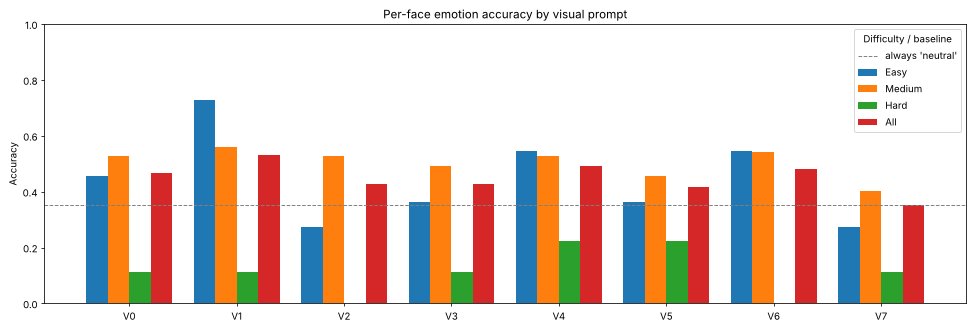

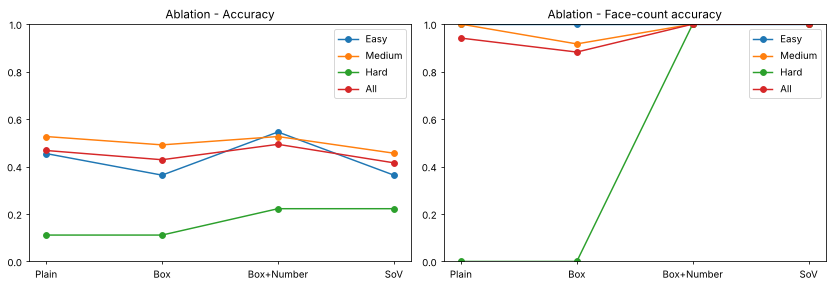

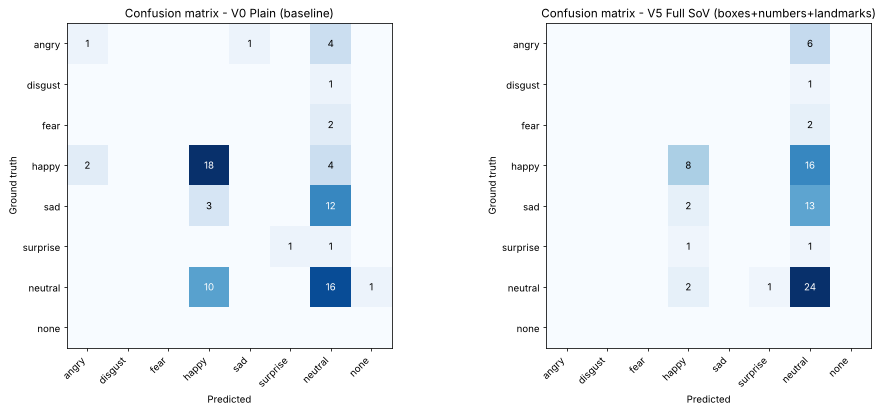

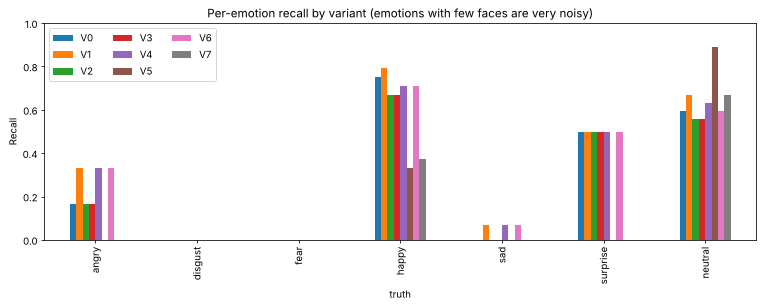

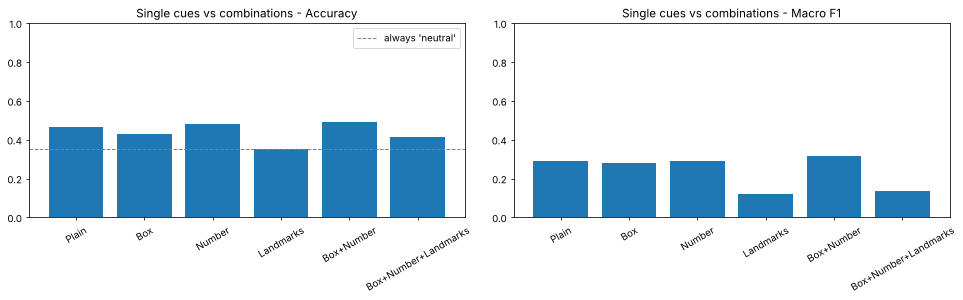

In [3]:
plots.accuracy_by_variant(M, VARIANTS, res["maj"], res["maj_class"], FIG)
plots.ablation(M, FIG)
plots.confusion(FACES, ("V0_plain", "V5_sov_full"), FIG)
plots.per_class(res["per_class"], VARIANTS, FIG)
plots.cue_isolation(M, res["maj"], res["maj_class"], FIG)

In [4]:
# Failure cases: images where full SoV did better / worse than the plain image (needs the photos)
have_photos = "path" in DATA[0] and Path(DATA[0]["path"]).exists()
if have_photos:
    notes = plots.failure_cases(res["eval_data"], FACES, IMGS, RES / "failures")
    print("\n".join(notes) if notes else "No image where plain and SoV differ.")
else:
    print("Photos not available here - skipping failure-case pictures (existing ones in", RES / "failures", "are kept).")
    print((RES / "failures" / "notes.txt").read_text() if (RES / "failures" / "notes.txt").exists() else "")

Photos not available here - skipping failure-case pictures (existing ones in /home/claude/repo/sov-emotion-recognition/results/Qwen_Qwen2-VL-7B-Instruct/failures are kept).
SoV better | image11.jpg | truth=['neutral', 'happy', 'neutral'] | plain=['happy', 'happy', 'happy'] | sov=['neutral', 'happy', 'neutral']
SoV better | image10.jpg | truth=['angry', 'sad', 'sad', 'fear', 'neutral', 'sad', 'sad', 'angry', 'neutral'] | plain=['neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'none'] | sov=['neutral', 'happy', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral', 'neutral']
SoV better | image3.jpg | truth=['neutral', 'neutral', 'neutral', 'surprise', 'sad'] | plain=['neutral', 'happy', 'neutral', 'neutral', 'neutral'] | sov=['neutral', 'neutral', 'neutral', 'neutral', 'neutral']
Plain better | image19.jpg | truth=['happy', 'happy', 'happy', 'happy'] | plain=['happy', 'happy', 'happy', 'happy'] | sov=['neutral', 'happy', 'neutral', 'neut

In [5]:
# Comparison with the paper (GPT-4V, its own 119-image dataset): compare the PATTERN, not the absolute numbers.
pd.options.display.float_format = "{:.1f}".format
CMP = plots.paper_comparison(M, VARIANTS)
print(CMP.to_string(index=False))
CMP.to_csv(RES / "paper_vs_ours.csv", index=False)

                              Variant  Easy (paper)  Easy (ours)  Medium (paper)  Medium (ours)  Hard (paper)  Hard (ours)  Total acc (paper)  Total acc (ours)  Recall (paper R@1)  Recall (ours, macro)
                  V0 Plain (baseline)          48.9         45.5            48.0           52.6          32.5         11.1               44.4              46.8                22.1                  28.7
   V1 RedCircle-style (circle + blur)          51.7         72.7            48.5           56.1          45.6         11.1               49.0              53.2                23.9                  33.7
         V2 ReCLIP-style (box + blur)          54.0         27.3            46.2           52.6          42.1          0.0               48.1              42.9                23.0                  27.0
                        V3 Boxes only          47.1         36.4            45.6           49.1          39.5         11.1               44.7              42.9                23.5             

## Report text
The final report (setup, results, analysis, limitations, Phase 3 findings) is in `REPORT.md` at the repo root.
Write the interpretation yourself from the numbers above.